# 00 - MNIST-784 Dataset Exploration

## Objective


Explore the MNIST handwritten digit dataset obtained from OpenML.

Steps:

1. Dataset acquisition from OpenML.
2. Target distribution analysis.
3. Digit visualization.
4. Two-dimensional UMAP visualization on the raw 784 pixels.

## Imports

In [15]:
import gc

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import polars.selectors as cs
import umap

from mnist_rbf import load_mnist, load_mnist_split, save_figure


/home/cudi/projects/mnist-rbf/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Dataset Acquisition

In [2]:
df = load_mnist()

Loading MNIST from local storage.


In [3]:
# Dataset dimensions
print("Rows:", df.height)
print("Columns:", df.width)

df.group_by('label').head(1).sort("label")

Rows: 70000
Columns: 785


label,pixel_0,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,pixel_9,pixel_10,pixel_11,pixel_12,pixel_13,pixel_14,pixel_15,pixel_16,pixel_17,pixel_18,pixel_19,pixel_20,pixel_21,pixel_22,pixel_23,pixel_24,pixel_25,pixel_26,pixel_27,pixel_28,pixel_29,pixel_30,pixel_31,pixel_32,pixel_33,pixel_34,pixel_35,…,pixel_747,pixel_748,pixel_749,pixel_750,pixel_751,pixel_752,pixel_753,pixel_754,pixel_755,pixel_756,pixel_757,pixel_758,pixel_759,pixel_760,pixel_761,pixel_762,pixel_763,pixel_764,pixel_765,pixel_766,pixel_767,pixel_768,pixel_769,pixel_770,pixel_771,pixel_772,pixel_773,pixel_774,pixel_775,pixel_776,pixel_777,pixel_778,pixel_779,pixel_780,pixel_781,pixel_782,pixel_783
u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,…,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,…,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,…,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,…,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,…,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,…,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
5,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,…,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
6,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,…,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
7,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,…,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
8,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,…,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


## Target Distribution

Explore the number of observations for each digit.

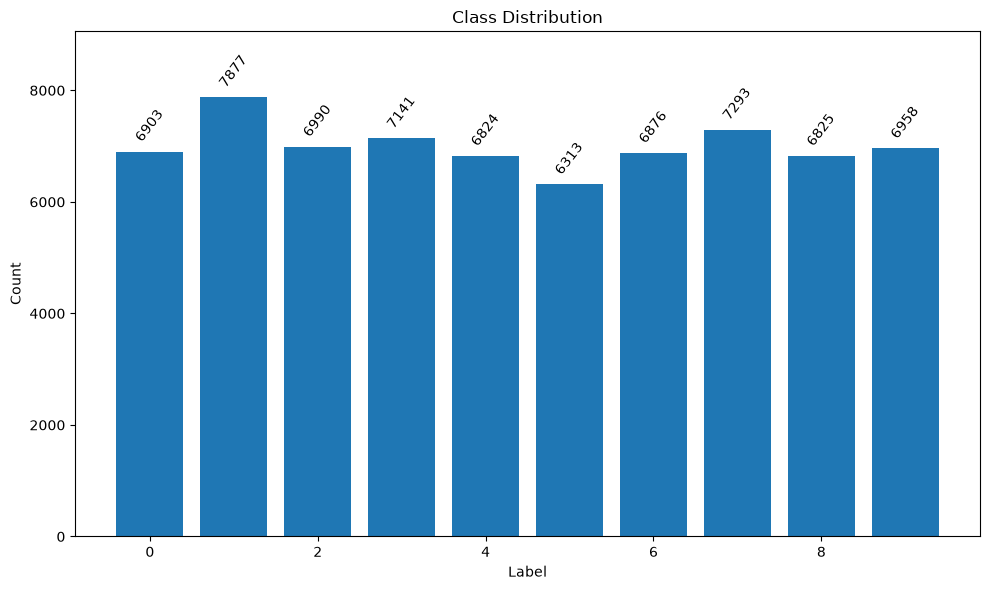

In [4]:
class_distribution = df.group_by("label").agg(pl.len()).sort("label")

labels = class_distribution["label"].to_list()
counts = class_distribution["len"].to_list()

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(labels, counts)

for bar, count in zip(bars, counts):
    ax.annotate(
        str(count),
        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom",
        rotation=52.5,
        fontsize=10
    )

ax.set_xlabel("Label")
ax.set_ylabel("Count")
ax.set_title("Class Distribution")
ax.margins(y=0.15)

plt.tight_layout()

save_figure(fig, "class-distribution.png")

plt.show()

## Digit Visualization

### Random Samples

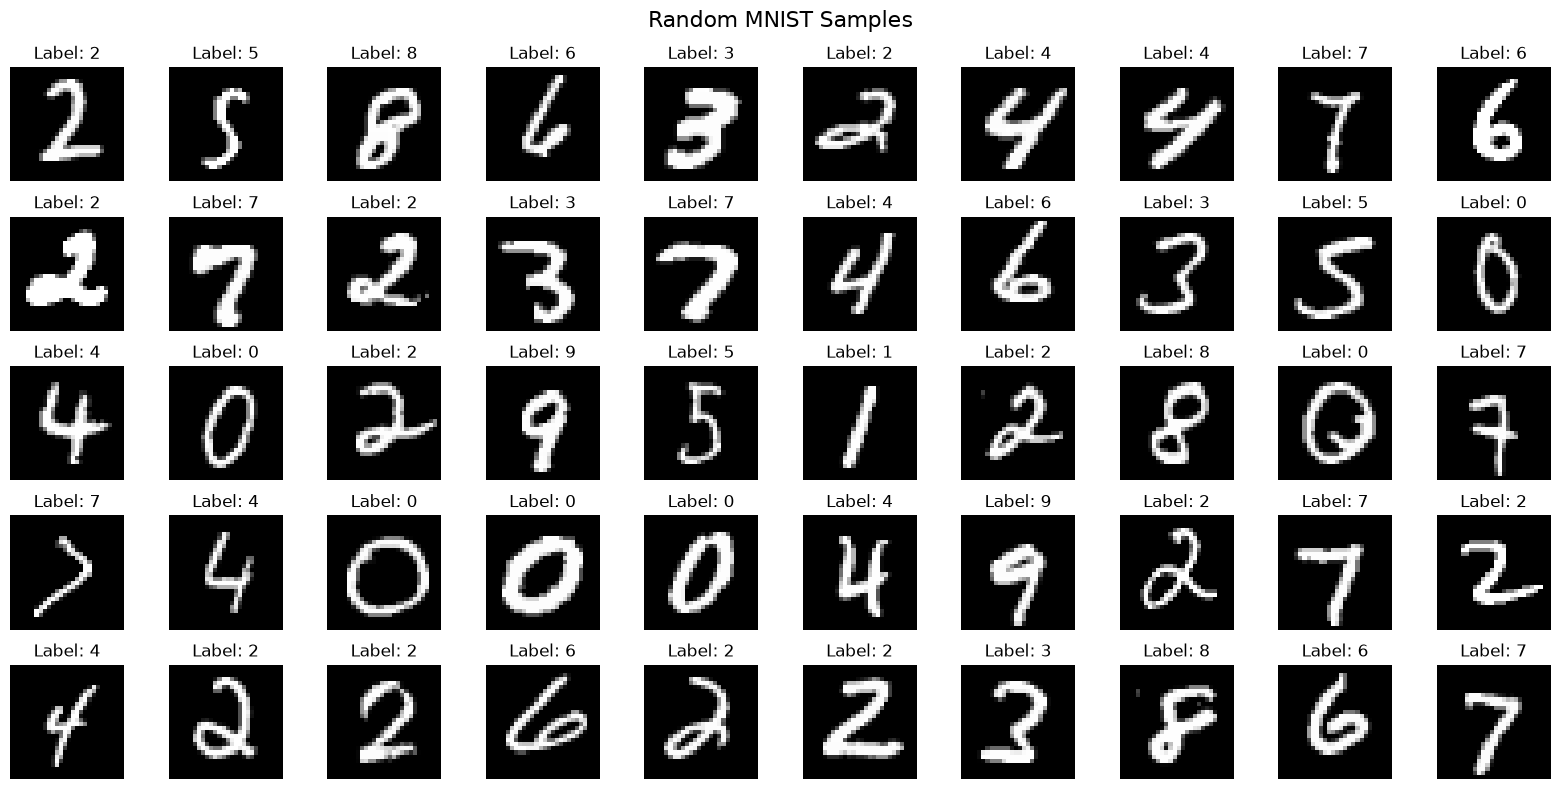

In [5]:
n_samples = 50
n_cols = 10

samples = df.sample(
    n=n_samples,
    seed=42,
).select(pl.concat_arr(cs.matches(r"pixel_\d+")).alias("pixels"), "label")

fig, axes = plt.subplots(
    n_samples // n_cols,
    n_cols,
    figsize=(16, 8),
)

for ax, row in zip(axes.flat, samples.iter_rows(named=True)):
    image = np.array(row["pixels"]).reshape(28, 28)

    ax.imshow(image, cmap="gray")
    ax.set_title(f"Label: {row['label']}")
    ax.axis("off")

plt.suptitle("Random MNIST Samples", fontsize=16)
plt.tight_layout()

save_figure(fig, "random-mnist-samples.png")

plt.show()

### Average image per digit

In [6]:
pixel_average = df.group_by("label").agg(cs.matches(r"pixel_\d+").mean()).sort("label").select(
    pl.concat_arr(cs.matches(r"pixel_\d+")).alias("pixel_average"), "label"
)

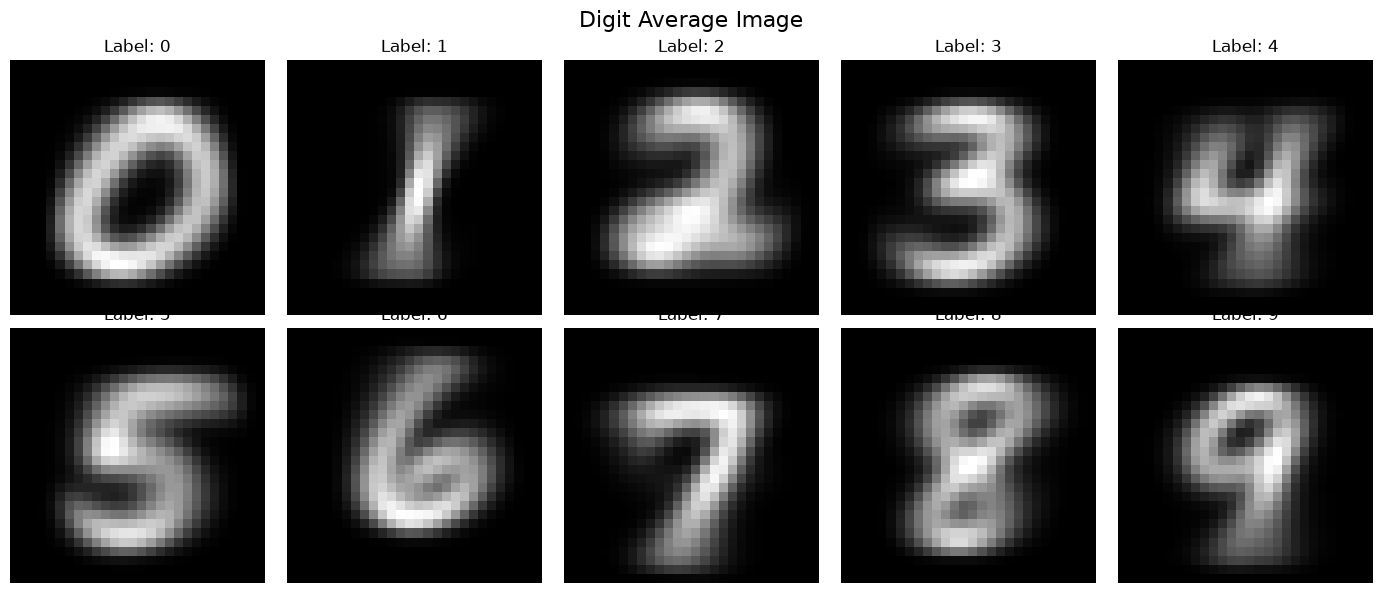

In [7]:
fig, axes = plt.subplots(
    2,
    5,
    figsize=(14, 6),
)

for ax, row in zip(axes.flat, pixel_average.iter_rows(named=True)):
    image = np.array(row["pixel_average"]).reshape(28, 28)

    ax.imshow(image, cmap="gray")
    ax.set_title(f"Label: {row['label']}")
    ax.axis("off")

plt.suptitle("Digit Average Image", fontsize=16)
plt.tight_layout()

save_figure(fig, "digit-average-images.png")

plt.show()

## Raw Pixel UMAP Visualization

Project the original 784-dimensional pixel representation directly into two dimensions using UMAP. Pixel intensities are scaled to [0, 1].


In [14]:
X_train, X_test, y_train, y_test = load_mnist_split(scale=True, dtype=np.float32)
X_pixels  = np.concat([X_train, X_test])
y = np.concat([y_train, y_test])

del X_train, X_test, y_train, y_test
gc.collect()

Loading MNIST from local storage.


0

In [16]:
umap_model = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    metric="euclidean",
    random_state=42,
    low_memory=True,
    verbose=True,
)

# Fit directly on all 784 raw pixel features.
X_umap = umap_model.fit_transform(X_pixels)

print("UMAP embedding shape:", X_umap.shape)

/home/cudi/projects/mnist-rbf/.venv/lib/python3.13/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/home/cudi/projects/mnist-rbf/.venv/lib/python3.13/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP(n_jobs=1, random_state=42, verbose=True)
Tue Nov 24 15:55:38 2026 Construct fuzzy simplicial set
Tue Nov 24 15:55:38 2026 Finding Nearest Neighbors
Tue Nov 24 15:55:38 2026 Using PyNNDescent with 0.5.x settings to find nearest neighbors (RINND not used: RINND >= 0.3.1 is not installed)
Tue Nov 24 15:55:38 2026 Building RP forest with 18 trees
Tue Nov 24 15:55:47 2026 NN descent for 16 iterations
	 1  /  16
	 2  /  16
	 3  /  16
	Stopping threshold met -- exiting after 3 iterations
Tue Nov 24 15:56:15 2026 Finished Nearest Neighbor Search
Tue Nov 24 15:56:19 2026 Construct embedding
Tue Nov 24 15:56:19 2026 Checking components for spectral layout...
Tue Nov 24 15:56:19 2026 Computing Laplacian...
Tue Nov 24 15:56:19 2026 Computing Eigenvectors...
Tue Nov 24 15:56:24 2026 Eigenvectors computed, ordering them...


Epochs completed: 100%| ██████████ 200/200 [00:24]


Tue Nov 24 15:56:49 2026 Finished embedding
UMAP embedding shape: (70000, 2)


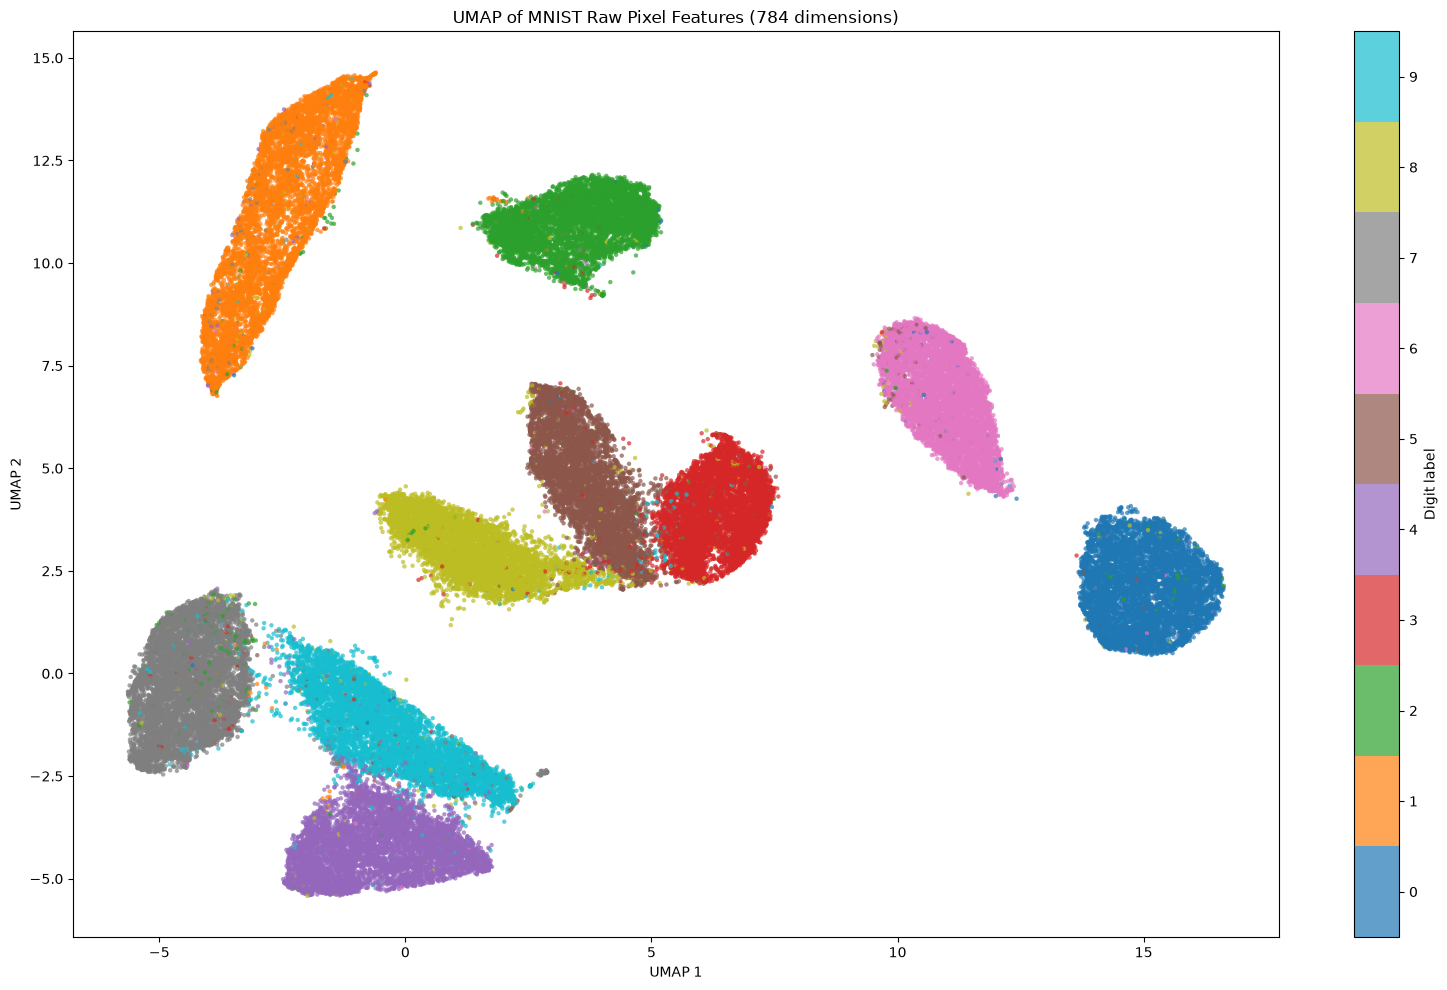

In [27]:
fig, ax = plt.subplots(figsize=(16, 10))

scatter = ax.scatter(
    X_umap[:, 0],
    X_umap[:, 1],
    c=y,
    cmap="tab10",
    norm=plt.Normalize(-0.5, 9.5),
    s=10,
    alpha=0.70,
    linewidths=0,
    rasterized=True,
)

colorbar = fig.colorbar(
    scatter,
    ax=ax,
    ticks=np.arange(10),
)
colorbar.set_label("Digit label")

ax.set_xlabel("UMAP 1")
ax.set_ylabel("UMAP 2")
ax.set_title("UMAP of MNIST Raw Pixel Features (784 dimensions)")

fig.tight_layout()
save_figure(fig, "mnist-raw-pixels-umap.png")
plt.show()